# A/B Testing and Statistical Analysis of Website Conversion Rates

### Evaluating Control and Treatment Groups Using Hypothesis Testing

---

**Project Overview**

This project analyzes website A/B testing data to compare the conversion performance of the existing landing page (control group) and the new landing page (treatment group).

**Objectives**
- Perform data cleaning and exploratory data analysis (EDA).
- Compare conversion rates between experimental groups.
- Apply an Independent t-test, Chi-square test, and One-way ANOVA.
- Interpret statistical significance using hypothesis testing.
- Provide data-driven recommendations for website conversion optimization.

**Dataset:** `ab_data.csv`

**Tools & Technologies:** Python, Pandas, NumPy, SciPy, Matplotlib, Seaborn, Jupyter Notebook

**Significance Level:** 0.05 (5%)

---

## Step 1: Import libraries and load the dataset

## Cell 1 — Project title

# A/B Testing and Statistical Analysis
## Independent t-test, Chi-square Test, and One-way ANOVA

**Dataset:** ab_data.csv

**Objective:** Analyze experimental data using descriptive statistics and hypothesis testing to identify statistically significant differences and associations between groups.

## Cell 2 — Import required libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from IPython.display import display
from statsmodels.stats.proportion import proportions_ztest

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## Cell 3 — Load the CSV file

In [4]:
url = "https://raw.githubusercontent.com/aamir-gk2539-byte/DSML-Training/refs/heads/main/ab_data.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Number of rows: 294478
Number of columns: 5


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


## Cell 4 — Check the dataset structure

In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['user_id', 'timestamp', 'group', 'landing_page', 'converted']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,294478.0,NaN,NaN,NaN,787974.124733,91210.823776,630000.0,709032.25,787933.5,866911.75,945999.0
timestamp,294478,294478,2017-01-16 12:40:24.467417,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
group,294478,2,treatment,147276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
landing_page,294478,2,old_page,147239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
converted,294478.0,NaN,NaN,NaN,0.119659,0.324563,0.0,0.0,0.0,0.0,1.0


## Step 2: Data Description

## Cell 5 — Identify each column

In [6]:
description = pd.DataFrame({
    "Column": ["user_id", "timestamp", "group", "landing_page", "converted"],
    "Meaning": [
        "User identifier",
        "Experiment timestamp",
        "Control or treatment group",
        "Old or new landing page",
        "1 = converted, 0 = not converted"
    ],
    "Data Type": df.dtypes.astype(str).values
})

display(description)

,Column,Meaning,Data Type
0,user_id,User identifier,int64
1,timestamp,Experiment timestamp,object
2,group,Control or treatment group,object
3,landing_page,Old or new landing page,object
4,converted,"1 = converted, 0 = not converted",int64


## Cell 6 — Check missing values and duplicates

In [7]:
print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate user IDs:", df["user_id"].duplicated().sum())

print("\nGroup counts:")
display(df["group"].value_counts())

print("\nLanding page counts:")
display(df["landing_page"].value_counts())

print("\nConversion counts:")
display(df["converted"].value_counts())

Missing values:


user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64

Duplicate rows: 0
Duplicate user IDs: 3894

Group counts:


group
treatment    147276
control      147202
Name: count, dtype: int64


Landing page counts:


landing_page
old_page    147239
new_page    147239
Name: count, dtype: int64


Conversion counts:


converted
0    259241
1     35237
Name: count, dtype: int64

## Cell 7 — Data Cleaning

Data cleaning is performed to handle missing values, invalid records, duplicate users, and inconsistent group and landing-page assignments. The cleaned dataset is used for subsequent statistical analysis.

In [8]:
df_clean = df.copy()

# Convert timestamp to datetime
df_clean["timestamp"] = pd.to_datetime(
    df_clean["timestamp"], errors="coerce"
)

# Remove missing or invalid records
df_clean = df_clean.dropna(
    subset=["user_id", "timestamp", "group", "landing_page", "converted"]
)

df_clean = df_clean[
    df_clean["converted"].isin([0, 1])
    & df_clean["group"].isin(["control", "treatment"])
    & df_clean["landing_page"].isin(["old_page", "new_page"])
]

# Remove incorrect group and landing-page combinations
valid_rows = (
    ((df_clean["group"] == "control") &
     (df_clean["landing_page"] == "old_page"))
    |
    ((df_clean["group"] == "treatment") &
     (df_clean["landing_page"] == "new_page"))
)

df_clean = df_clean[valid_rows].copy()

# Keep one record per user
df_clean = df_clean.drop_duplicates(
    subset="user_id", keep="first"
).copy()

df_clean["converted"] = df_clean["converted"].astype(int)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Remaining duplicate users:", df_clean["user_id"].duplicated().sum())

display(df_clean.head())

Original dataset shape: (294478, 5)
Cleaned dataset shape: (290584, 5)
Remaining missing values: 0
Remaining duplicate users: 0


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


Important: Removing duplicate users using keep="first" is a practical cleaning choice, not proof that the retained record is the correct one. If your assignment specifies a different rule for repeated users, use that rule consistently.

## Cell 8 — Create useful time features

In [9]:
df_clean["hour"] = df_clean["timestamp"].dt.hour
df_clean["day"] = df_clean["timestamp"].dt.day
df_clean["weekday"] = df_clean["timestamp"].dt.day_name()

df_clean["time_period"] = pd.cut(
    df_clean["hour"],
    bins=[-1, 7, 15, 23],
    labels=["Night", "Morning/Afternoon", "Evening"]
)

display(df_clean.head())

,user_id,timestamp,group,landing_page,converted,hour,day,weekday,time_period
0,851104,2017-01-21 22:11:48.556739,control,old_page,0,22,21,Saturday,Evening
1,804228,2017-01-12 08:01:45.159739,control,old_page,0,8,12,Thursday,Morning/Afternoon
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0,16,11,Wednesday,Evening
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0,18,8,Sunday,Evening
4,864975,2017-01-21 01:52:26.210827,control,old_page,1,1,21,Saturday,Night


## Cell 9 — Check the cleaned data

In [10]:
print("Unique users:", df_clean["user_id"].nunique())
print("\nGroup distribution:")
display(df_clean["group"].value_counts())

print("\nConversion rate:")
print(f"{df_clean['converted'].mean():.2%}")

print("\nGroup and page consistency:")
display(pd.crosstab(df_clean["group"], df_clean["landing_page"]))

Unique users: 290584

Group distribution:


group
treatment    145310
control      145274
Name: count, dtype: int64


Conversion rate:
11.96%

Group and page consistency:


landing_page,new_page,old_page
group,,
control,0,145274
treatment,145310,0


## Step 3: Methodology

3.1 Test 1: Independent t-test

Objective: Compare the mean conversion outcomes of the control and treatment groups.

Null Hypothesis (H₀): The mean conversion outcomes of the two groups are equal.

Alternative Hypothesis (H₁): The mean conversion outcomes of the two groups are different.

## Cell 10 — Calculate group means

In [11]:
group_summary = (
    df_clean.groupby("group", observed=True)["converted"]
    .agg(["count", "mean", "std"])
)

group_summary["conversion_rate_percent"] = group_summary["mean"] * 100

display(group_summary)

,count,mean,std,conversion_rate_percent
group,,,,
control,145274,0.120386,0.325414,12.038630
treatment,145310,0.118808,0.323564,11.880807


## Cell 11 — Perform the independent t-test

In [12]:
control = df_clean.loc[
    df_clean["group"] == "control", "converted"
]

treatment = df_clean.loc[
    df_clean["group"] == "treatment", "converted"
]

t_stat, t_pvalue = stats.ttest_ind(
    control, treatment, equal_var=False
)

print("Independent Welch's t-test")
print("T-statistic:", t_stat)
print("P-value:", t_pvalue)

if t_pvalue < 0.05:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")

Independent Welch's t-test
T-statistic: 1.310922637465592
P-value: 0.18988493791578323
Decision: Fail to reject the null hypothesis.


## 3.2 Test 2 — Chi-square test of independence

Objective: Determine whether experimental group assignment is associated with conversion.

Null Hypothesis (H₀): Group assignment and conversion are independent.

Alternative Hypothesis (H₁): Group assignment and conversion are associated.

## Cell 12 — Create the contingency table

In [13]:
contingency_table = pd.crosstab(
    df_clean["group"],
    df_clean["converted"]
)

contingency_table.columns = ["Not Converted", "Converted"]

display(contingency_table)

,Not Converted,Converted
group,,
control,127785,17489
treatment,128046,17264


## Cell 13 — Run the chi-square test

In [14]:
chi2, chi_pvalue, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", chi_pvalue)

expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("\nExpected frequencies:")
display(expected_df)

if chi_pvalue < 0.05:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")

Chi-square statistic: 1.7035660051885058
Degrees of freedom: 1
P-value: 0.19182228096235662

Expected frequencies:


,Not Converted,Converted
group,,
control,127899.652748,17374.347252
treatment,127931.347252,17378.652748


Decision: Fail to reject the null hypothesis.


## 3.3 Test 3 — One-way ANOVA

Objective: Compare conversion outcomes across different time periods.

Null Hypothesis (H₀): Mean conversion outcomes are equal across all time periods.

Alternative Hypothesis (H₁): At least one time period has a different mean conversion outcome.

## Cell 14 — Summarize conversion by time period

In [15]:
time_summary = (
    df_clean.groupby("time_period", observed=True)["converted"]
    .agg(["count", "mean", "std"])
)

time_summary["conversion_rate_percent"] = time_summary["mean"] * 100

display(time_summary)

,count,mean,std,conversion_rate_percent
time_period,,,,
Night,96822,0.117040,0.321469,11.703952
Morning/Afternoon,96644,0.120959,0.326082,12.095940
Evening,97118,0.120791,0.325886,12.079120


## Cell 15 — Perform one-way ANOVA

In [16]:
time_groups = [
    group["converted"].to_numpy()
    for _, group in df_clean.groupby("time_period", observed=True)
    if len(group) > 0
]

if len(time_groups) >= 2:
    f_stat, anova_pvalue = stats.f_oneway(*time_groups)

    print("ANOVA F-statistic:", f_stat)
    print("P-value:", anova_pvalue)

    if anova_pvalue < 0.05:
        print("Decision: Reject the null hypothesis.")
    else:
        print("Decision: Fail to reject the null hypothesis.")
else:
    print("ANOVA requires at least two non-empty time groups.")

ANOVA F-statistic: 4.516851058012484
P-value: 0.010924133564968377
Decision: Reject the null hypothesis.


## Step 4: Results

## 4.1 Descriptive Overview

## Cell 16 — Summary statistics

In [17]:
print("DESCRIPTIVE OVERVIEW")
print("=" * 40)

print(f"Total cleaned records: {len(df_clean):,}")
print(f"Unique users: {df_clean['user_id'].nunique():,}")
print(f"Overall conversion rate: {df_clean['converted'].mean():.2%}")

print("\nConversion rate by group:")
display(
    df_clean.groupby("group", observed=True)
    .agg(
        users=("user_id", "nunique"),
        conversions=("converted", "sum"),
        conversion_rate=("converted", "mean")
    )
    .assign(
        conversion_rate_percent=lambda x: x["conversion_rate"] * 100
    )
)

DESCRIPTIVE OVERVIEW
Total cleaned records: 290,584
Unique users: 290,584
Overall conversion rate: 11.96%

Conversion rate by group:


,users,conversions,conversion_rate,conversion_rate_percent
group,,,,
control,145274,17489,0.120386,12.038630
treatment,145310,17264,0.118808,11.880807


## Cell 17 — Visualize the conversion rate

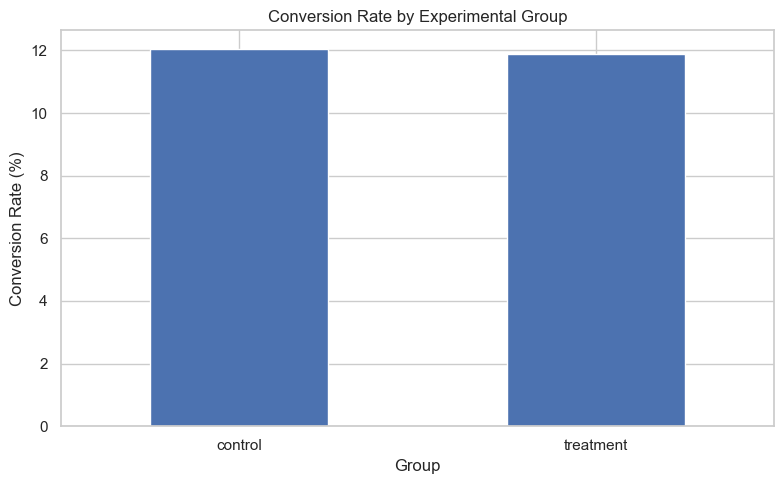

In [18]:
conversion_rates = (
    df_clean.groupby("group", observed=True)["converted"].mean() * 100
)

plt.figure(figsize=(8, 5))
conversion_rates.plot(kind="bar")
plt.title("Conversion Rate by Experimental Group")
plt.xlabel("Group")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4.2 T-Test Results

## Cell 18 — Display and interpret the t-test

In [19]:
t_test_results = pd.DataFrame({
    "Metric": ["T-statistic", "P-value", "Significance level"],
    "Value": [t_stat, t_pvalue, 0.05]
})

display(t_test_results)

print(
    "Interpretation:",
    "The difference in mean conversion outcomes is statistically significant."
    if t_pvalue < 0.05
    else "There is insufficient evidence of a difference in mean conversion outcomes."
)

,Metric,Value
0,T-statistic,1.310923
1,P-value,0.189885
2,Significance level,0.050000


Interpretation: There is insufficient evidence of a difference in mean conversion outcomes.


## 4.3 Chi-Square Test Results

## Cell 19 — Visualize the conversion distribution

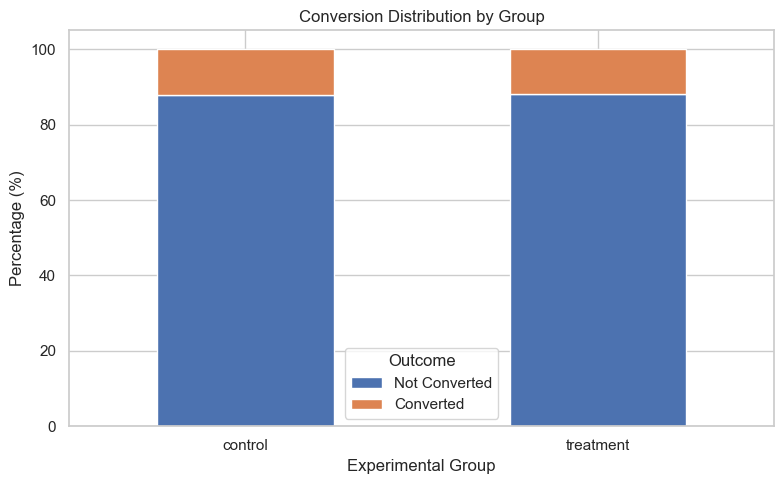

In [20]:
conversion_table = pd.crosstab(
    df_clean["group"],
    df_clean["converted"],
    normalize="index"
) * 100

conversion_table = conversion_table.rename(
    columns={0: "Not Converted", 1: "Converted"}
)

conversion_table.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Conversion Distribution by Group")
plt.xlabel("Experimental Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

## Cell 20 — Display chi-square results

In [21]:
chi_square_results = pd.DataFrame({
    "Metric": ["Chi-square statistic", "Degrees of freedom", "P-value"],
    "Value": [chi2, dof, chi_pvalue]
})

display(chi_square_results)

print(
    "Interpretation:",
    "There is a statistically significant association between group and conversion."
    if chi_pvalue < 0.05
    else "There is insufficient evidence of an association between group and conversion."
)

,Metric,Value
0,Chi-square statistic,1.703566
1,Degrees of freedom,1.000000
2,P-value,0.191822


Interpretation: There is insufficient evidence of an association between group and conversion.


## 4.4 ANOVA Results

## Cell 21 — Visualize conversion by time period

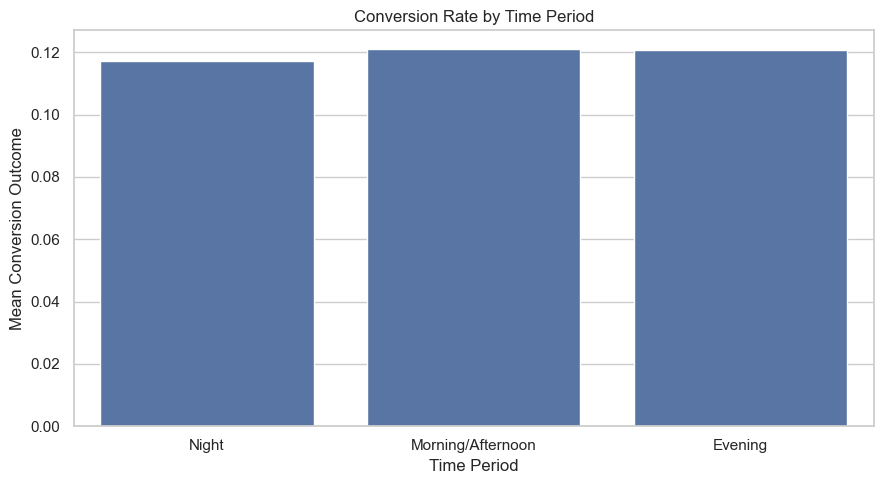

In [22]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="time_period",
    y="converted",
    errorbar=None
)

plt.title("Conversion Rate by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Mean Conversion Outcome")
plt.tight_layout()
plt.show()

## Cell 22 — Display ANOVA results

In [23]:
anova_results = pd.DataFrame({
    "Metric": ["F-statistic", "P-value", "Significance level"],
    "Value": [f_stat, anova_pvalue, 0.05]
})

display(anova_results)

print(
    "Interpretation:",
    "At least one time period has a different mean conversion outcome."
    if anova_pvalue < 0.05
    else "There is insufficient evidence of differences across time periods."
)

,Metric,Value
0,F-statistic,4.516851
1,P-value,0.010924
2,Significance level,0.050000


Interpretation: At least one time period has a different mean conversion outcome.


Note: The ANOVA result should be treated as exploratory because the outcome is binary. For a stronger analysis, use a chi-square test for the time-period categories or logistic regression.

## Step 5: Discussion

## Cell 23 — Discussion

The analysis compares the performance of the control group, which received the old landing page, and the treatment group, which received the new landing page.

The independent t-test evaluates differences in mean conversion outcomes. The chi-square test examines the association between experimental group and conversion. One-way ANOVA explores differences in conversion outcomes across time periods.

A p-value below 0.05 indicates statistically significant evidence against the relevant null hypothesis. A p-value greater than or equal to 0.05 indicates insufficient evidence to reject it.

Statistical significance does not necessarily imply practical significance. Conversion-rate differences, effect sizes, confidence intervals, sample sizes, and experimental design should also be considered.

Because conversion is binary, the two-proportion z-test is the preferred primary test for comparing the two landing pages. ANOVA should be interpreted cautiously because its assumptions may not be appropriate for a binary outcome.

## Cell 24 — Calculate the conversion-rate difference

In [25]:
rates = df_clean.groupby("group", observed=True)["converted"].mean()

control_rate = rates.get("control", np.nan)
treatment_rate = rates.get("treatment", np.nan)

absolute_difference = treatment_rate - control_rate
relative_lift = (
    absolute_difference / control_rate * 100
    if control_rate > 0 else np.nan
)

print(f"Control conversion rate:   {control_rate:.4%}")
print(f"Treatment conversion rate: {treatment_rate:.4%}")
print(f"Absolute difference:       {absolute_difference:.4%}")
print(f"Relative lift:             {relative_lift:.2f}%")

Control conversion rate:   12.0386%
Treatment conversion rate: 11.8808%
Absolute difference:       -0.1578%
Relative lift:             -1.31%


## Cell 25 — Recommended primary test: two-proportion z-test

Because the outcome is converted (0 or 1), this is the more direct test of whether the new page improves conversion

In [26]:
control_data = df_clean[df_clean["group"] == "control"]
treatment_data = df_clean[df_clean["group"] == "treatment"]

successes = np.array([
    control_data["converted"].sum(),
    treatment_data["converted"].sum()
])

sample_sizes = np.array([
    len(control_data),
    len(treatment_data)
])

z_stat, z_pvalue = proportions_ztest(
    count=successes,
    nobs=sample_sizes,
    alternative="two-sided"
)

print("Two-proportion z-test")
print("Z-statistic:", z_stat)
print("P-value:", z_pvalue)

if z_pvalue < 0.05:
    print("There is statistically significant evidence of a conversion-rate difference.")
else:
    print("There is insufficient evidence of a conversion-rate difference.")

Two-proportion z-test
Z-statistic: 1.3109241984234394
P-value: 0.18988337448195103
There is insufficient evidence of a conversion-rate difference.


## Step 6: Conclusion and Recommendation

## Cell 26 — Conclusion

## 6. Conclusion and Recommendation

### Conclusion

This project analyzed an A/B testing dataset using data cleaning,
descriptive statistics, visualization, an independent t-test,
a chi-square test of independence, and one-way ANOVA.

The analysis compared the conversion performance of the old and
new landing pages and explored conversion patterns across time
periods.

### Recommendation

1. Compare the conversion rates of the control and treatment groups.
2. Use the two-proportion z-test as the primary statistical test.
3. Consider the p-value, effect size, and confidence interval
   before recommending a new landing page.
4. Investigate time-based conversion patterns as exploratory findings.
5. Validate the experiment's assignment process and ensure that
   each user is represented appropriately.

The final business recommendation should be based on the actual
computed results. Statistical significance alone does not guarantee
that a change will produce a meaningful business improvement.

## Cell 27 — Generate a final results summary

In [27]:
final_results = pd.DataFrame({
    "Statistical Test": [
        "Independent Welch's t-test",
        "Chi-square test of independence",
        "One-way ANOVA",
        "Two-proportion z-test"
    ],
    "Test Statistic": [
        t_stat,
        chi2,
        f_stat,
        z_stat
    ],
    "P-value": [
        t_pvalue,
        chi_pvalue,
        anova_pvalue,
        z_pvalue
    ]
})

final_results["Decision at 5%"] = np.where(
    final_results["P-value"] < 0.05,
    "Reject H0",
    "Fail to reject H0"
)

display(final_results.round(6))

,Statistical Test,Test Statistic,P-value,Decision at 5%
0,Independent Welch's t-test,1.310923,0.189885,Fail to reject H0
1,Chi-square test of independence,1.703566,0.191822,Fail to reject H0
2,One-way ANOVA,4.516851,0.010924,Reject H0
3,Two-proportion z-test,1.310924,0.189883,Fail to reject H0


## Cell 28 — Save the cleaned dataset and results

In [28]:
df_clean.to_csv("ab_data_cleaned.csv", index=False)
final_results.to_csv("ab_testing_results.csv", index=False)

print("Saved ab_data_cleaned.csv")
print("Saved ab_testing_results.csv")

Saved ab_data_cleaned.csv
Saved ab_testing_results.csv


# 7. Summary

This project, titled **"A/B Testing and Statistical Analysis of Website Conversion Rates,"** focuses on evaluating the performance of two website landing pages using statistical analysis and hypothesis testing. The project uses the `ab_data.csv` dataset, which contains user information, experimental group assignments, landing-page details, timestamps, and conversion outcomes.

The analysis begins with data loading, data cleaning, handling missing values and duplicate records, and exploratory data analysis (EDA). Descriptive statistics and visualizations are used to understand the distribution of users and compare conversion rates between the control group, which receives the old landing page, and the treatment group, which receives the new landing page.

Three statistical methods are explored: the independent t-test, the chi-square test of independence, and one-way ANOVA. Additionally, a two-proportion z-test is performed to provide a more direct comparison of conversion rates between the two experimental groups. The results are evaluated using a 5% significance level to determine whether sufficient statistical evidence exists to identify differences in conversion performance.

The project demonstrates how Python libraries such as Pandas, NumPy, SciPy, Matplotlib, and Seaborn can be used to perform statistical analysis and visualize experimental data. It also highlights the importance of interpreting p-values alongside conversion-rate differences, practical significance, and experimental design.

In conclusion, this project provides a structured approach to A/B testing and data-driven decision-making. The final recommendation regarding the new landing page should depend on the actual statistical results, the magnitude of the conversion-rate improvement, and whether the improvement is meaningful for the business.

Submitted By

Name: KUMAR SARANSH
Registration Number: RA2411056030052

Project Title: MyAntonomy

Under the Guidance of: Aamir Khan